# Notebook 3 — Review a draft against its source

Run a greeting, a question the folder can't answer, and a question answered by the Walker Ranch text. Then review the draft about PNC's loss rate against the original page and edit the answer if it uses the wrong column.

The graph uses `interrupt` to pause for review and `Command(resume=...)` to apply your decision. Open `check` and `human_review` in `document_rag.py` while you read the graph below. The question cells call Qwen several times, so allow about a minute per cell.


In [1]:
from pathlib import Path
import sys

HERE = Path.cwd().resolve()
if not (HERE / "document_rag.py").exists():
    raise SystemExit("Set the notebook's working directory to 16_agentic_document_rag.")
sys.path.insert(0, str(HERE))

import document_rag as desk
from document_rag import ask

assistant = desk.get_assistant()
assistant.get_graph().print_ascii()  # the same edges as the comment above route()


                                                               +-----------+                                                                    
                                                               | __start__ |......                                                              
                                                               +-----------+      ............                                                  
                                                                ..                            .............                                     
                                                              ..                                           .............                        
                                                             .                                                          ............            
                                                      +----------+                                                                

## How to read the picture

```text
route            greeting                  -> chat -> END
                 anything else             -> retrieve -> grade

after_grade      at least one hit          -> generate -> check
                 no hits, budget left      -> rewrite -> retrieve
                 no hits, budget spent     -> abstain

after_check      draft says NOT_IN_CORPUS  -> abstain
                 a number is not in the    -> rewrite, or abstain if the
                 passages, or the checker     budget is spent
                 said no
                 supported, and the hit    -> human_review
                 is a table or a figure,
                 or the draft has a
                 measured number
                 supported prose           -> END

after_human      approve or edit           -> END
                 reject, budget left       -> rewrite
                 reject, budget spent      -> abstain
```

`human_review` calls `interrupt`. LangGraph runs that function again from the top when the person resumes, and `interrupt` then returns the decision. Do not put work above that call. It would run twice.

Two support checks run, and both must pass, before a person is asked to sign:

1. Every measured number in the draft (`5.4%`, `18,443.87`) has to appear in a retrieved passage. The chat model's own "yes" is not enough.
2. The structured `Check` schema has to say the claims are in the passages.

A failed check does not go to the person. It rewrites once, then abstains. A year by itself, such as 2020, does not count as a measured number. A percent, a decimal, or a thousands-separator does.

The digit check does not know which column a number belongs to. Both `1.7` and `5.4%` can be in the passage, and the draft can still swap them. That is why the person sees the page.


## 1. Compare three questions

Run the cell and read the path for each question.

- A greeting goes straight to `chat`.
- The question about HarborDesk leave uses one retry, then returns `NOT_IN_CORPUS`.
- The Walker Ranch answer comes from the paragraphs about the red dots. In the saved run, the graph sends the prose answer directly.


In [2]:
def show(question):
    values, payload = ask(question)
    print("Q:", question)
    for step in values["steps"]:
        print(" ", step)
    if payload:
        print("PAUSED:", payload["reason"])
        print(payload["draft"])
    else:
        print(values["answer"])
    print()
    return values, payload

greeting, _ = show("Good morning")
miss, _ = show("How many annual leave days does a full-time HarborDesk employee receive?")
walker, walker_pause = show("In the Walker Ranch seismic figures, what do the red dots show?")
print("walker waited for a person:", walker_pause is not None)


Q: Good morning
  chat (documents stay closed)
I'm here to help you with anything you need!



Q: How many annual leave days does a full-time HarborDesk employee receive?
  retrieve 'How many annual leave days does a full-time HarborDesk employee receive?' -> [2025833 p.5 text], [1659677 p.4 text], [2025833 p.5 text], [0082969 p.6 text]
  grade [2025833 p.5 text]=no, [1659677 p.4 text]=no, [2025833 p.5 text]=no, [0082969 p.6 text]=no
  rewrite -> 'HarborDesk full-time annual leave days'
  retrieve 'HarborDesk full-time annual leave days' -> [6002966 p.9 text], [6838482 p.8 text], [6002966 p.2 text], [6002966 p.1 text]
  grade [6002966 p.9 text]=no, [6838482 p.8 text]=no, [6002966 p.2 text]=no, [6002966 p.1 text]=no
  abstain
NOT_IN_CORPUS: the loaded documents do not answer that question.



Q: In the Walker Ranch seismic figures, what do the red dots show?
  retrieve 'In the Walker Ranch seismic figures, what do the red dots show?' -> [walker_ranch_seismic p.1 text], [walker_ranch_seismic p.1 text], [walker_ranch_seismic p.1 figure], [walker_ranch_seismic p.1 text]
  grade [walker_ranch_seismic p.1 text]=yes, [walker_ranch_seismic p.1 text]=yes, [walker_ranch_seismic p.1 figure]=no, [walker_ranch_seismic p.1 text]=no
  generate
  check digits=yes model=yes
In Figure 3, the red dots show locations of micro-earthquakes [walker_ranch_seismic p.1 text]. In Figure 2, the red dots indicate micro-earthquakes within 2000 feet of the section [walker_ranch_seismic p.1 text].

walker waited for a person: False


## 2. Check the PNC draft

On page 7, find the Commercial Real Estate row in Table 5. **$1.7 billion** is the net charge-off amount. **5.4%** is the portfolio loss rate.

The saved draft used 1.7 as the percentage. Both numbers were in the retrieved caption, so the digit check passed. The figure still triggered review. Open the page image and verify which column answers the question before you send the draft.


  retrieve 'In PNC's adverse scenario covering Q3 2017 through Q3 2019, what is the estimated loss percentage for Commercial Real Estate?' -> [7257900 p.7 figure], [7257900 p.7 text], [7257900 p.3 text], [7257900 p.6 figure]
  grade [7257900 p.7 figure]=yes, [7257900 p.7 text]=no, [7257900 p.3 text]=no, [7257900 p.6 figure]=no
  generate
  check digits=yes model=yes

The evidence is a table or a figure. A person signs the draft before it is treated as sent.
The estimated loss percentage for Commercial Real Estate is 1.7%, which increases to 5.4%. [7257900 p.7 figure]
thread: desk-df4704dc


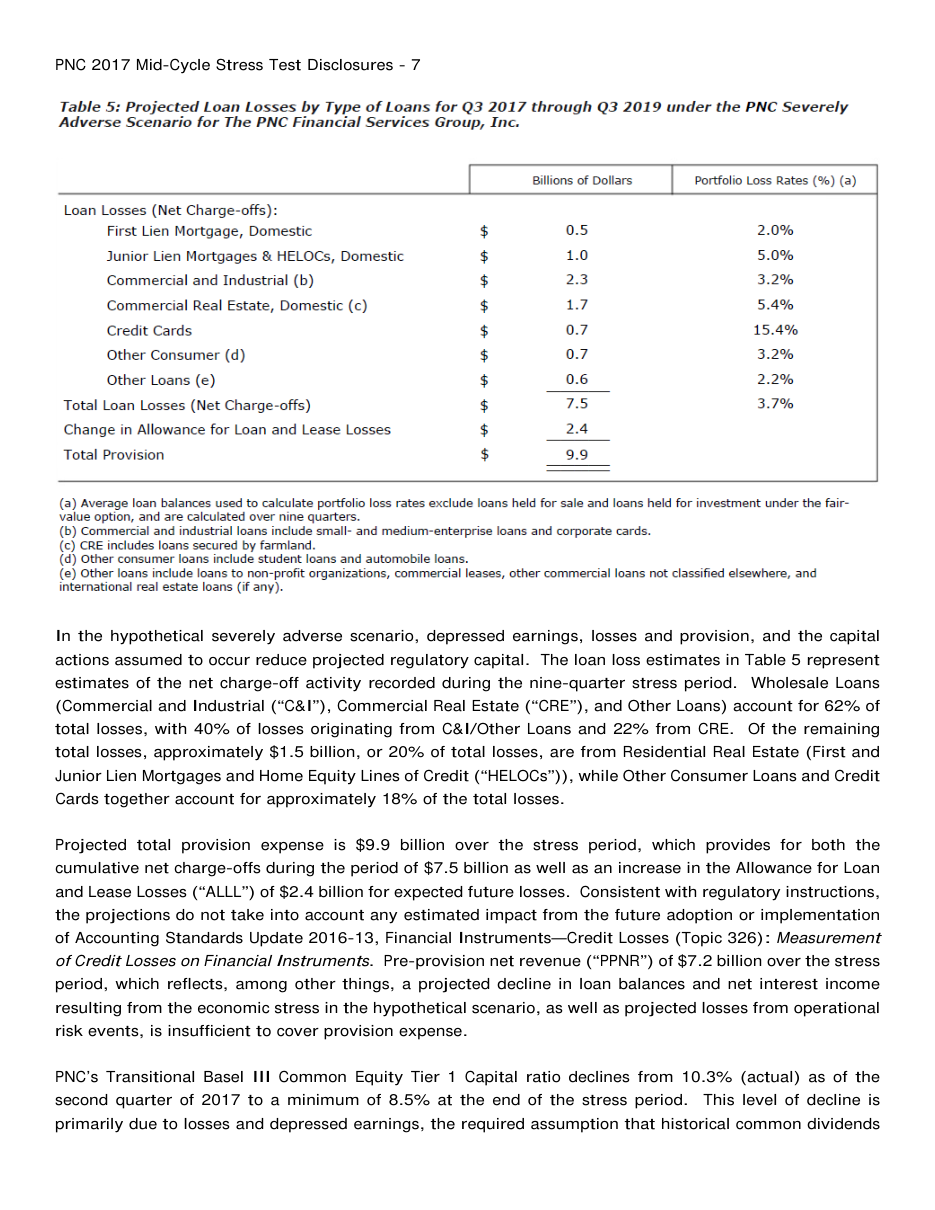

In [3]:
from IPython.display import Image, display

pnc = (
    "In PNC's adverse scenario covering Q3 2017 through Q3 2019, "
    "what is the estimated loss percentage for Commercial Real Estate?"
)
pnc_values, pnc_pause = ask(pnc)
for step in pnc_values["steps"]:
    print(" ", step)
print()
print(pnc_pause["reason"])
print(pnc_pause["draft"])
print("thread:", pnc_values["thread_id"])
display(Image(filename=str(HERE / "corpus/pages/7257900/page_007.png")))


## 3. Edit and send the draft

Resume with the same thread ID and choose `edit`. The graph sends the text you enter and uses it as the final answer.

To see what happens when you reject a draft, try the exercise below.


In [4]:
edited = (
    "Commercial Real Estate, Domestic has a portfolio loss rate of 5.4% "
    "($1.7 billion of net charge-offs) under the severely adverse scenario. "
    "[7257900 p.7 figure]"
)
final, again = ask("", thread_id=pnc_values["thread_id"], resume={"action": "edit", "text": edited})
print("paused again:", again is not None)
print("human_action:", final["human_action"])
print(final["answer"])


paused again: False
human_action: edit
Commercial Real Estate, Domestic has a portfolio loss rate of 5.4% ($1.7 billion of net charge-offs) under the severely adverse scenario. [7257900 p.7 figure]


## Exercise

Start a **new** question so you get a new thread. Use the PNC question again. Resume it with `{"action": "reject"}`.

Write down the next step after `human rejected the draft`.

<details><summary>Answer</summary>

`rewrites_left` is still 1, because the first pass was supported and never rewrote. Reject therefore takes the `rewrite` edge, searches once more, and then either pauses again or abstains. A second reject finds the budget spent and abstains.

</details>


## The same graph, with buttons

The Streamlit app is this graph plus the page image next to the draft.

```bash
streamlit run app.py
```

| Button | What it does |
|---|---|
| Approve and send | The draft leaves as written |
| Send the edited text | The path you just ran. The typed text replaces the draft |
| Reject and search again | One more search, then a new pause or an abstain |

The buttons sit in a form so the edited text and the click are sent together. A plain button can fire before Streamlit has stored the edit, and the original wrong draft leaves.

The checkpointer is in memory. Restarting the app drops a draft that was waiting. A production desk swaps `MemorySaver` for a sqlite or postgres checkpointer. The nodes do not change.
